# Loan Default Risk Analysis

## Project Overview
This project analyses LendingClub loan data to identify patterns associated with loan defaults.

## Business Objectives
- Analyse borrower characteristics.
- Understand loan default patterns.
- Identify high-risk loan categories.
- Provide data-driven business recommendations.

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
file_path = r"C:\Users\Tulsi\Downloads\accepted_2007_to_2018q4.csv\accepted_2007_to_2018Q4.csv"

print("File path saved successfully!")

File path saved successfully!


In [3]:
df_columns = pd.read_csv(file_path, nrows=0)

print("Total columns:", len(df_columns.columns))
print(df_columns.columns.tolist())

Total columns: 151
['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint'

In [4]:
selected_columns = [
    'loan_amnt',
    'term',
    'int_rate',
    'grade',
    'sub_grade',
    'emp_length',
    'home_ownership',
    'annual_inc',
    'verification_status',
    'loan_status',
    'purpose',
    'dti',
    'delinq_2yrs',
    'revol_util',
    'total_acc',
    'issue_d'
]

print("Selected columns:", len(selected_columns))

Selected columns: 16


In [5]:
df = pd.read_csv(
    file_path,
    usecols=selected_columns,
    nrows=100000,
    low_memory=False
)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

Dataset loaded successfully!
Rows and columns: (100000, 16)


In [6]:
df.head()

,loan_amnt,term,int_rate,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,dti,delinq_2yrs,revol_util,total_acc
0,3600.0,36 months,13.99,C,C4,10+ years,MORTGAGE,55000.0,Not Verified,Dec-2015,Fully Paid,debt_consolidation,5.91,0.0,29.7,13.0
1,24700.0,36 months,11.99,C,C1,10+ years,MORTGAGE,65000.0,Not Verified,Dec-2015,Fully Paid,small_business,16.06,1.0,19.2,38.0
2,20000.0,60 months,10.78,B,B4,10+ years,MORTGAGE,63000.0,Not Verified,Dec-2015,Fully Paid,home_improvement,10.78,0.0,56.2,18.0
3,35000.0,60 months,14.85,C,C5,10+ years,MORTGAGE,110000.0,Source Verified,Dec-2015,Current,debt_consolidation,17.06,0.0,11.6,17.0
4,10400.0,60 months,22.45,F,F1,3 years,MORTGAGE,104433.0,Source Verified,Dec-2015,Fully Paid,major_purchase,25.37,1.0,64.5,35.0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   loan_amnt            100000 non-null  float64
 1   term                 100000 non-null  object 
 2   int_rate             100000 non-null  float64
 3   grade                100000 non-null  object 
 4   sub_grade            100000 non-null  object 
 5   emp_length           93888 non-null   object 
 6   home_ownership       100000 non-null  object 
 7   annual_inc           100000 non-null  float64
 8   verification_status  100000 non-null  object 
 9   issue_d              100000 non-null  object 
 10  loan_status          100000 non-null  object 
 11  purpose              100000 non-null  object 
 12  dti                  99998 non-null   float64
 13  delinq_2yrs          100000 non-null  float64
 14  revol_util           99963 non-null   float64
 15  total_acc         

In [8]:
df.shape

(100000, 16)

In [9]:
df['loan_status'].value_counts()

loan_status
Fully Paid            70288
Charged Off           17603
Current               11402
Late (31-120 days)      441
In Grace Period         199
Late (16-30 days)        66
Default                   1
Name: count, dtype: int64

In [10]:
df['loan_status'].value_counts(normalize=True).mul(100).round(2)

loan_status
Fully Paid            70.29
Charged Off           17.60
Current               11.40
Late (31-120 days)     0.44
In Grace Period        0.20
Late (16-30 days)      0.07
Default                0.00
Name: proportion, dtype: float64

In [11]:
df['issue_d'].value_counts().head(10)

issue_d
Dec-2015    44343
Nov-2015    37360
Oct-2015    18297
Name: count, dtype: int64

In [12]:
print("Unique loan issue months:", df['issue_d'].nunique())

print("\nEarliest loan date:")
print(df['issue_d'].min())

print("\nLatest loan date:")
print(df['issue_d'].max())

Unique loan issue months: 3

Earliest loan date:
Dec-2015

Latest loan date:
Oct-2015


In [13]:
df['issue_date'] = pd.to_datetime(
    df['issue_d'],
    format='%b-%Y'
)

print("Earliest date:", df['issue_date'].min())
print("Latest date:", df['issue_date'].max())

print("\nMonthly record count:")
print(df['issue_date'].dt.to_period('M').value_counts().sort_index())

Earliest date: 2015-10-01 00:00:00
Latest date: 2015-12-01 00:00:00

Monthly record count:
issue_date
2015-10    18297
2015-11    37360
2015-12    44343
Freq: M, Name: count, dtype: int64


In [14]:
print("Total records:", len(df))
print("Duplicate rows:", df.duplicated().sum())

Total records: 100000
Duplicate rows: 0


In [15]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage': (missing_values / len(df) * 100).round(2)
})

missing_summary[missing_summary['Missing Count'] > 0]

,Missing Count,Missing Percentage
emp_length,6112,6.11
dti,2,0.00
revol_util,37,0.04


In [16]:
df_clean = df.copy()

# Fill missing employment length
df_clean['emp_length'] = df_clean['emp_length'].fillna('Unknown')

# Remove rows with missing DTI or revolving utilisation
df_clean = df_clean.dropna(subset=['dti', 'revol_util'])

print("Original records:", len(df))
print("Clean records:", len(df_clean))
print("Remaining missing values:", df_clean.isnull().sum().sum())

Original records: 100000
Clean records: 99961
Remaining missing values: 0


In [17]:
# Create a default indicator
df_clean['default_flag'] = np.where(
    df_clean['loan_status'].isin(['Charged Off', 'Default']),
    1,
    np.where(df_clean['loan_status'] == 'Fully Paid', 0, np.nan)
)

# Check loan outcome categories
print(df_clean['default_flag'].value_counts(dropna=False))

default_flag
0.0    70259
1.0    17595
NaN    12107
Name: count, dtype: int64


In [18]:
# Keep only completed loan outcomes
outcome_df = df_clean.dropna(subset=['default_flag']).copy()

# Calculate default rate
default_rate = outcome_df['default_flag'].mean() * 100

print("Total completed loans:", len(outcome_df))
print("Default rate:", round(default_rate, 2), "%")
print("Repaid loans:", (outcome_df['default_flag'] == 0).sum())
print("Defaulted loans:", (outcome_df['default_flag'] == 1).sum())

Total completed loans: 87854
Default rate: 20.03 %
Repaid loans: 70259
Defaulted loans: 17595


In [19]:
grade_analysis = (
    outcome_df.groupby('grade')
    .agg(
        total_loans=('default_flag', 'count'),
        defaulted_loans=('default_flag', 'sum'),
        default_rate=('default_flag', 'mean')
    )
)

grade_analysis['default_rate'] = (
    grade_analysis['default_rate'] * 100
).round(2)

grade_analysis = grade_analysis.sort_index()

grade_analysis

,total_loans,defaulted_loans,default_rate
grade,,,
A,17056,907.0,5.32
B,28017,3698.0,13.20
C,24477,5801.0,23.70
D,10942,3772.0,34.47
E,5493,2409.0,43.86
F,1532,809.0,52.81
G,337,199.0,59.05


In [20]:
outcome_df['interest_group'] = pd.cut(
    outcome_df['int_rate'],
    bins=[0, 8, 12, 16, 20, 30],
    labels=['Below 8%', '8–12%', '12–16%', '16–20%', 'Above 20%']
)

interest_analysis = outcome_df.groupby(
    'interest_group', observed=True
).agg(
    total_loans=('default_flag', 'count'),
    defaulted_loans=('default_flag', 'sum'),
    default_rate=('default_flag', 'mean')
)

interest_analysis['default_rate'] = (
    interest_analysis['default_rate'] * 100
).round(2)

interest_analysis

,total_loans,defaulted_loans,default_rate
interest_group,,,
Below 8%,17089,909.0,5.32
8–12%,30500,4202.0,13.78
12–16%,25027,6197.0,24.76
16–20%,12656,4930.0,38.95
Above 20%,2582,1357.0,52.56


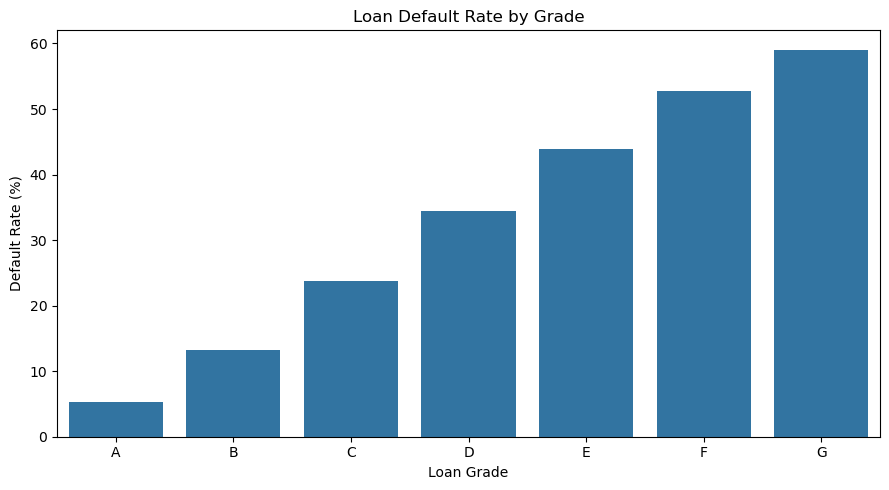

In [21]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=grade_analysis.index,
    y=grade_analysis['default_rate']
)

plt.title('Loan Default Rate by Grade')
plt.xlabel('Loan Grade')
plt.ylabel('Default Rate (%)')
plt.tight_layout()
plt.show()

In [22]:
purpose_analysis = outcome_df.groupby('purpose').agg(
    total_loans=('default_flag', 'count'),
    defaulted_loans=('default_flag', 'sum'),
    default_rate=('default_flag', 'mean')
)

purpose_analysis['default_rate'] = (
    purpose_analysis['default_rate'] * 100
).round(2)

purpose_analysis = purpose_analysis.sort_values(
    'default_rate', ascending=False
)

purpose_analysis

,total_loans,defaulted_loans,default_rate
purpose,,,
small_business,778,233.0,29.95
house,280,75.0,26.79
moving,534,121.0,22.66
medical,1036,231.0,22.30
debt_consolidation,49630,10832.0,21.83
renewable_energy,54,11.0,20.37
other,4904,945.0,19.27
major_purchase,1763,338.0,19.17
home_improvement,5580,999.0,17.90


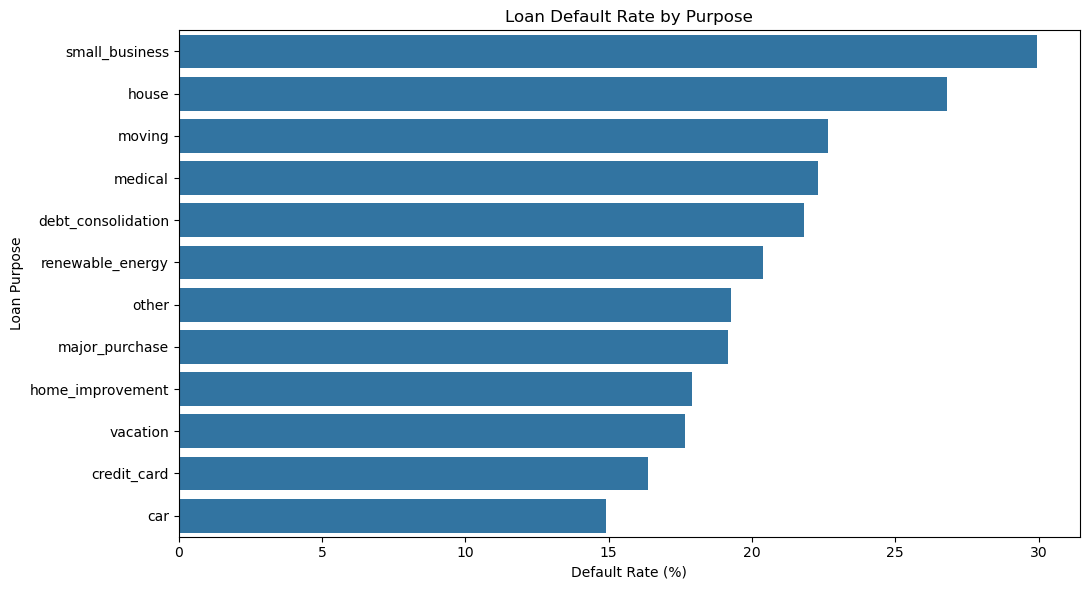

In [23]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=purpose_analysis.reset_index(),
    x='default_rate',
    y='purpose'
)

plt.title('Loan Default Rate by Purpose')
plt.xlabel('Default Rate (%)')
plt.ylabel('Loan Purpose')
plt.tight_layout()
plt.show()

In [24]:
outcome_df['annual_inc'].describe()

count    8.785400e+04
mean     7.767992e+04
std      8.968340e+04
min      1.200000e+03
25%      4.600000e+04
50%      6.500000e+04
75%      9.255925e+04
max      9.000000e+06
Name: annual_inc, dtype: float64

In [25]:
outcome_df['income_group'] = pd.cut(
    outcome_df['annual_inc'],
    bins=[0, 25000, 50000, 75000, 100000, 150000, np.inf],
    labels=[
        'Below 25K',
        '25K–50K',
        '50K–75K',
        '75K–100K',
        '100K–150K',
        'Above 150K'
    ],
    include_lowest=True
)

income_analysis = outcome_df.groupby(
    'income_group', observed=True
).agg(
    total_loans=('default_flag', 'count'),
    defaulted_loans=('default_flag', 'sum'),
    default_rate=('default_flag', 'mean')
)

income_analysis['default_rate'] = (
    income_analysis['default_rate'] * 100
).round(2)

income_analysis

,total_loans,defaulted_loans,default_rate
income_group,,,
Below 25K,3407,782.0,22.95
25K–50K,24443,5461.0,22.34
50K–75K,26536,5646.0,21.28
75K–100K,16369,3078.0,18.80
100K–150K,12285,1973.0,16.06
Above 150K,4814,655.0,13.61


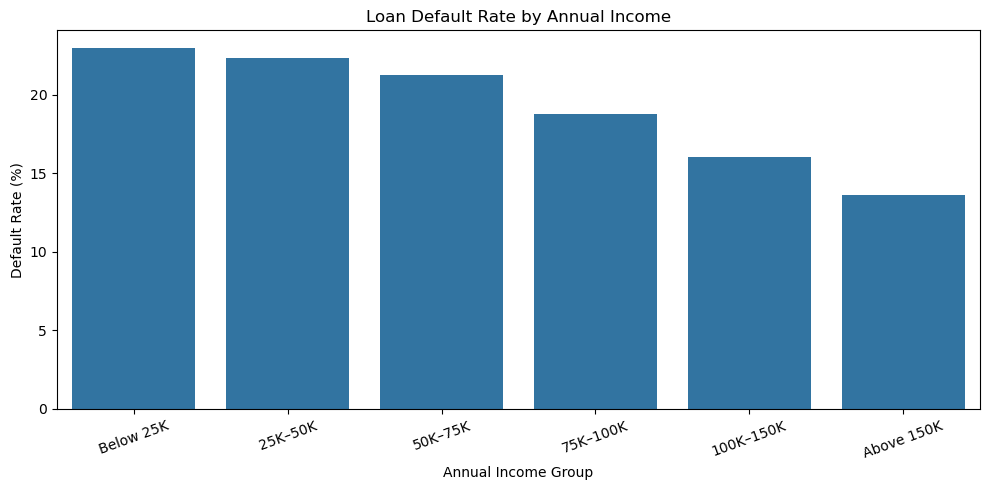

In [26]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=income_analysis.index,
    y=income_analysis['default_rate']
)

plt.title('Loan Default Rate by Annual Income')
plt.xlabel('Annual Income Group')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [27]:
employment_analysis = outcome_df.groupby(
    'emp_length', observed=True
).agg(
    total_loans=('default_flag', 'count'),
    defaulted_loans=('default_flag', 'sum'),
    default_rate=('default_flag', 'mean')
)

employment_analysis['default_rate'] = (
    employment_analysis['default_rate'] * 100
).round(2)

employment_analysis.sort_values(
    'default_rate', ascending=False
)

,total_loans,defaulted_loans,default_rate
emp_length,,,
Unknown,5626,1424.0,25.31
1 year,5785,1216.0,21.02
9 years,3353,703.0,20.97
< 1 year,7777,1601.0,20.59
5 years,5267,1084.0,20.58
3 years,7130,1448.0,20.31
8 years,4428,894.0,20.19
4 years,5062,1017.0,20.09
2 years,7706,1530.0,19.85


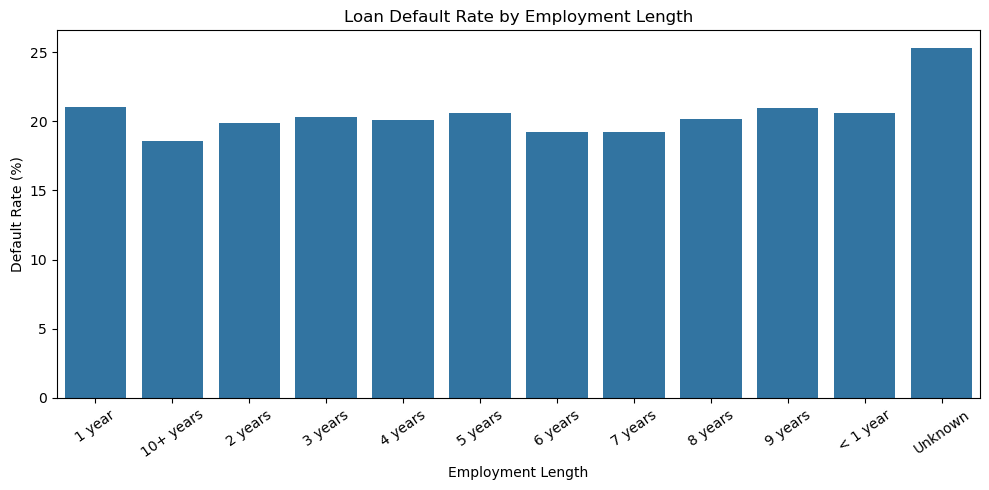

In [28]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=employment_analysis.reset_index().sort_values('emp_length'),
    x='emp_length',
    y='default_rate'
)

plt.title('Loan Default Rate by Employment Length')
plt.xlabel('Employment Length')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [29]:
df_clean.to_csv(
    'loan_data_cleaned.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [30]:
grade_analysis.to_csv('grade_analysis.csv')
interest_analysis.to_csv('interest_analysis.csv')
purpose_analysis.to_csv('purpose_analysis.csv')
income_analysis.to_csv('income_analysis.csv')
employment_analysis.to_csv('employment_analysis.csv')

print("All analysis reports saved successfully!")

All analysis reports saved successfully!
